# 02: Data Preprocessing and Demand Analytics (Phase 2)

Runs the Phase 2 pipeline (`src.preprocessing`, `src.demand_analytics`, `src.visualization`) and shows the key tables and figures. The full narrative is in `reports/phase2_preprocessing_eda.md`.

**Approved scope:** CONUS is the primary network, Puerto Rico a separate network, Hawaii is for analysis only, and international destinations are never routed.

In [1]:
import sys, os, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import pandas as pd
from IPython.display import Image, display
from src.preprocessing import run_preprocessing
from src.demand_analytics import run_demand_analytics
from src.visualization import make_phase2_figures
from src.reports import write_phase2_report
pd.set_option('display.width', 220, 'display.max_columns', 30, 'display.max_colwidth', 80)
pre = run_preprocessing(write=True)
tables = run_demand_analytics(pre.items, pre.orders, pre.zones, pre.zone_daily, write=True)
figs = make_phase2_figures(pre.zones, pre.zone_daily, tables)
write_phase2_report(pre, tables)

## 1. Cleaning-decision log (`data_quality_report.csv`)

In [2]:
pre.quality_log[['step','stage','rule','action','records_affected','orders_affected','units_affected','orders_remaining_in_demand_set']]

,step,stage,rule,action,records_affected,orders_affected,units_affected,orders_remaining_in_demand_set
0,1,load,Read raw DataCoSupplyChainDataset.csv (Latin-1),none,180519,65752,384079,65752
1,2,privacy,"Drop PII columns: Customer Fname, Customer Lname, Customer Street, Customer ...",drop columns,180519,0,0,<NA>
2,3,columns,Drop column 'Product Description',drop column,180519,0,0,<NA>
3,4,columns,Drop column 'Product Status',drop column,180519,0,0,<NA>
4,5,columns,Drop column 'Product Image',drop column,180519,0,0,<NA>
5,6,columns,Drop column 'Customer Zipcode',drop column,180519,0,0,<NA>
6,7,columns,Drop column 'Order Zipcode',drop column,180519,0,0,<NA>
7,8,columns,Rename columns to snake_case,rename,0,0,0,<NA>
8,9,validity,Unparseable order/shipping date,would exclude,0,0,0,<NA>
9,10,validity,Exact duplicate rows,would exclude,0,0,0,<NA>


## 2. Coordinate interpretation evidence

In [3]:
display(pre.coord_validation); display(tables['destination'])

,evidence,subject,n_customers,data_median_lat,data_median_lon,reference_lat,reference_lon,km_median_to_reference,p50_km_customer_to_city_median,p90_km_customer_to_city_median,value
0,reference city centre,"Chicago, IL",430,41.8953,-87.6933,41.8781,-87.6298,5.59,6.91,21.63,NaN
1,reference city centre,"Los Angeles, CA",392,34.0343,-118.2775,34.0522,-118.2437,3.69,7.80,14.71,NaN
2,reference city centre,"Brooklyn, NY",370,40.6457,-73.9452,40.6782,-73.9442,3.61,3.72,7.21,NaN
3,reference city centre,"Houston, TX",148,29.7806,-95.4245,29.7604,-95.3698,5.73,15.70,24.36,NaN
4,reference city centre,"New York, NY",193,40.7703,-73.9585,40.7128,-74.0060,7.55,4.85,13.77,NaN
5,reference city centre,"Philadelphia, PA",163,39.9586,-75.1819,39.9526,-75.1652,1.57,4.24,13.10,NaN
6,reference city centre,"San Diego, CA",154,32.7586,-117.1374,32.7157,-117.1611,5.26,4.97,20.01,NaN
7,reference city centre,"San Juan, PR",10,18.3860,-66.0940,18.4655,-66.1057,8.93,0.00,8.09,NaN
8,reference city centre,"Caguas, PR",7650,18.2486,-66.3705,18.2341,-66.0485,34.05,5.03,35.48,NaN
9,reference city centre,"Honolulu, HI",74,21.3056,-157.8387,21.3069,-157.8583,2.04,3.72,8.66,NaN


,test,chi2,dof,p_value,cramers_v,overall_domestic_share
0,destination_domestic vs network,6.799680,2,0.033379,0.010472,0.125478
1,destination_domestic vs customer_state (CONUS),58.225044,43,0.060536,0.039343,0.127628


## 3. Demand zones

,zones,customers,orders,units,max_radius_km
network,,,,,
CONUS,312,12204,37617,219308,46.545466
Hawaii,6,137,419,2384,4.576764
Puerto Rico,25,7700,23975,140273,7.341448


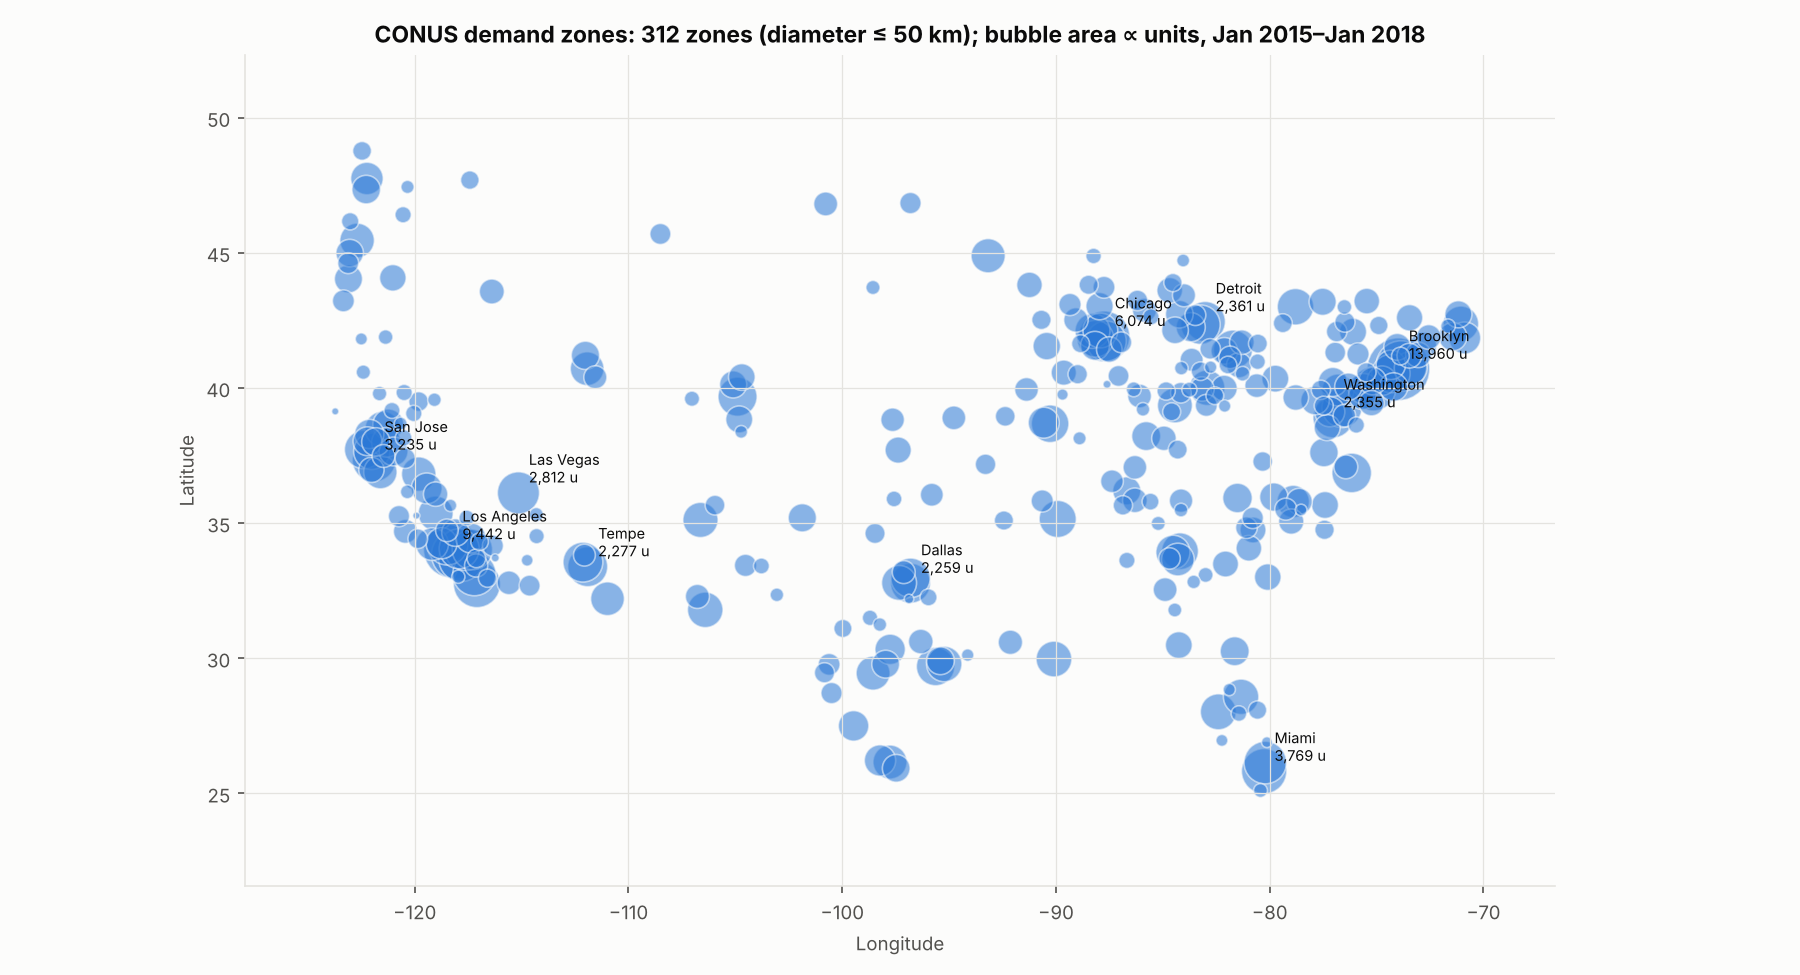

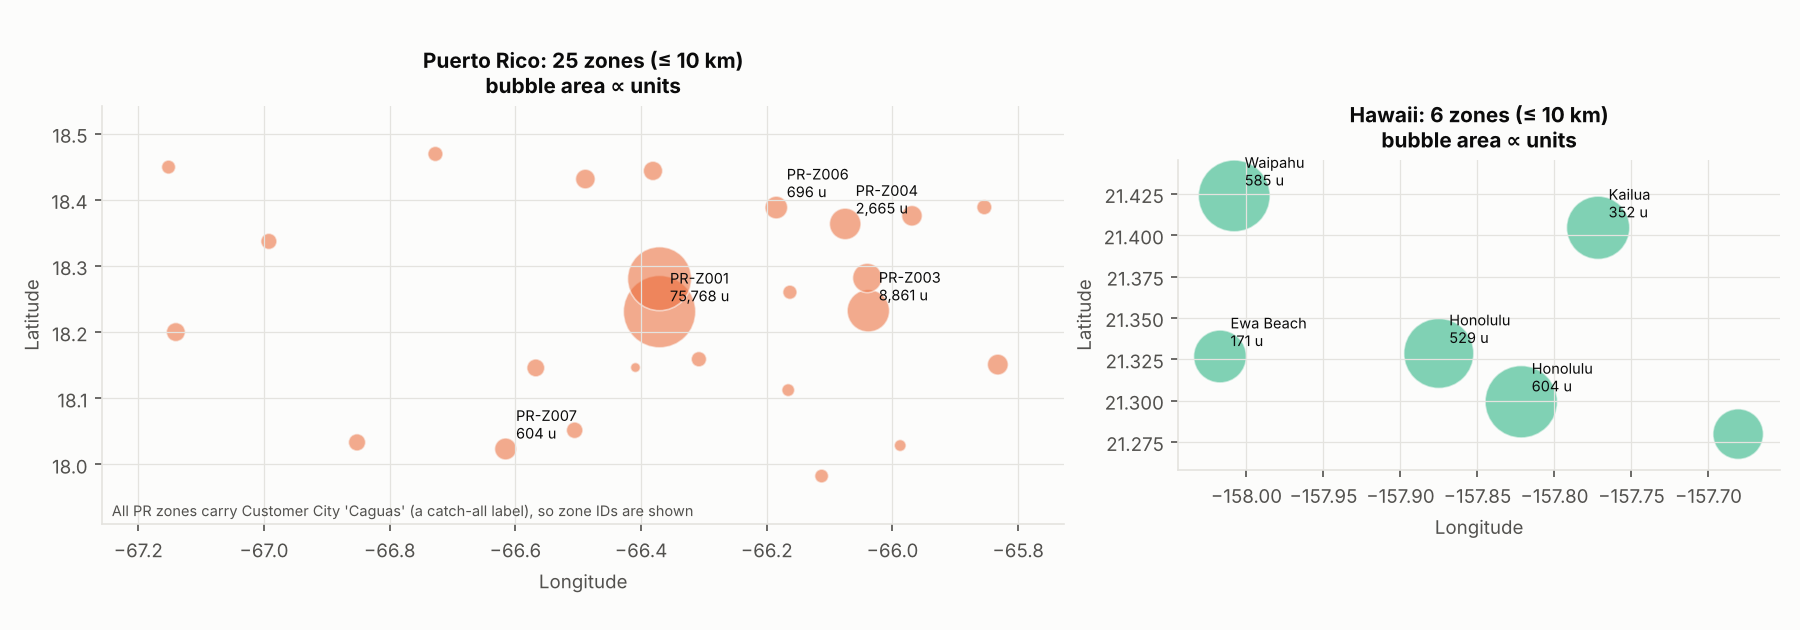

In [4]:
display(pre.zones.groupby('network').agg(zones=('zone_id','size'), customers=('n_customers','sum'), orders=('n_orders','sum'), units=('units','sum'), max_radius_km=('max_km_from_centroid','max')))
display(Image('reports/figures/phase2_demand_zones_conus.png')); display(Image('reports/figures/phase2_demand_zones_pr_hi.png'))

## 4. Aggregation validation (items → orders → zone-day)

In [5]:
rec = pre.reconciliation
print(f"{rec.passed.sum()}/{len(rec)} checks passed")
rec

37/37 checks passed


,network,check,value_a,value_b,passed
0,CONUS,units: items == orders,2.193080e+05,2.193080e+05,True
1,CONUS,units: orders == zone-day,2.193080e+05,2.193080e+05,True
2,CONUS,units: orders == zone table,2.193080e+05,2.193080e+05,True
3,CONUS,orders: distinct item order_id == order rows,3.761700e+04,3.761700e+04,True
4,CONUS,orders: order rows == zone-day orders,3.761700e+04,3.761700e+04,True
5,CONUS,items: item rows == sum n_items,1.032650e+05,1.032650e+05,True
6,CONUS,sales: items == zone-day,2.103776e+07,2.103776e+07,True
7,CONUS,every order has exactly one zone,0.000000e+00,0.000000e+00,True
8,CONUS,orders with >1 zone across items,0.000000e+00,0.000000e+00,True
9,CONUS,customers with >1 zone,0.000000e+00,0.000000e+00,True


## 5. Demand patterns and the 2017-10 change

,network,regime,first_day,last_day,calendar_days,days_with_orders,orders,units,orders_per_day,units_per_day,items_per_order,units_per_order,units_per_item,sales_per_order,customers,share_customers_seen_before_break,categories,top_category,markets
0,CONUS,pre_2017_10,2015-01-01,2017-09-30,1004,1004,32716,214193,32.585657,213.339641,3.003974,6.547041,2.179460,597.784051,7348,NaN,32,Cleats,5
1,CONUS,post_2017_10,2017-10-01,2018-01-31,123,123,4901,5115,39.845528,41.585366,1.017547,1.043665,1.025667,302.113528,4901,0.009182,31,Video Games,2
2,Hawaii,pre_2017_10,2015-01-05,2017-09-30,1004,310,364,2329,0.362550,2.319721,2.928571,6.398352,2.184803,592.564298,82,NaN,26,Cleats,5
3,Hawaii,post_2017_10,2017-10-06,2018-01-30,123,49,55,55,0.447154,0.447154,1.000000,1.000000,1.000000,301.839641,55,0.000000,17,Video Games,2
4,Puerto Rico,pre_2017_10,2015-01-01,2017-09-30,1004,1004,20919,137053,20.835657,136.506972,2.995124,6.551604,2.187423,597.086553,4676,NaN,32,Cleats,5
5,Puerto Rico,post_2017_10,2017-10-01,2018-01-31,123,123,3056,3220,24.845528,26.178862,1.019634,1.053665,1.033376,301.025884,3056,0.010471,31,Video Games,2


,network,zones,spearman_rho_zone_order_share,p_value,mean_abs_share_diff_pp,pearson_r
0,CONUS,312,0.933531,3.769176e-140,0.070155,0.983738
1,Hawaii,6,0.927634,7.665844e-03,3.290043,0.964309
2,Puerto Rico,25,0.705882,8.071098e-05,7.183122,-0.000029


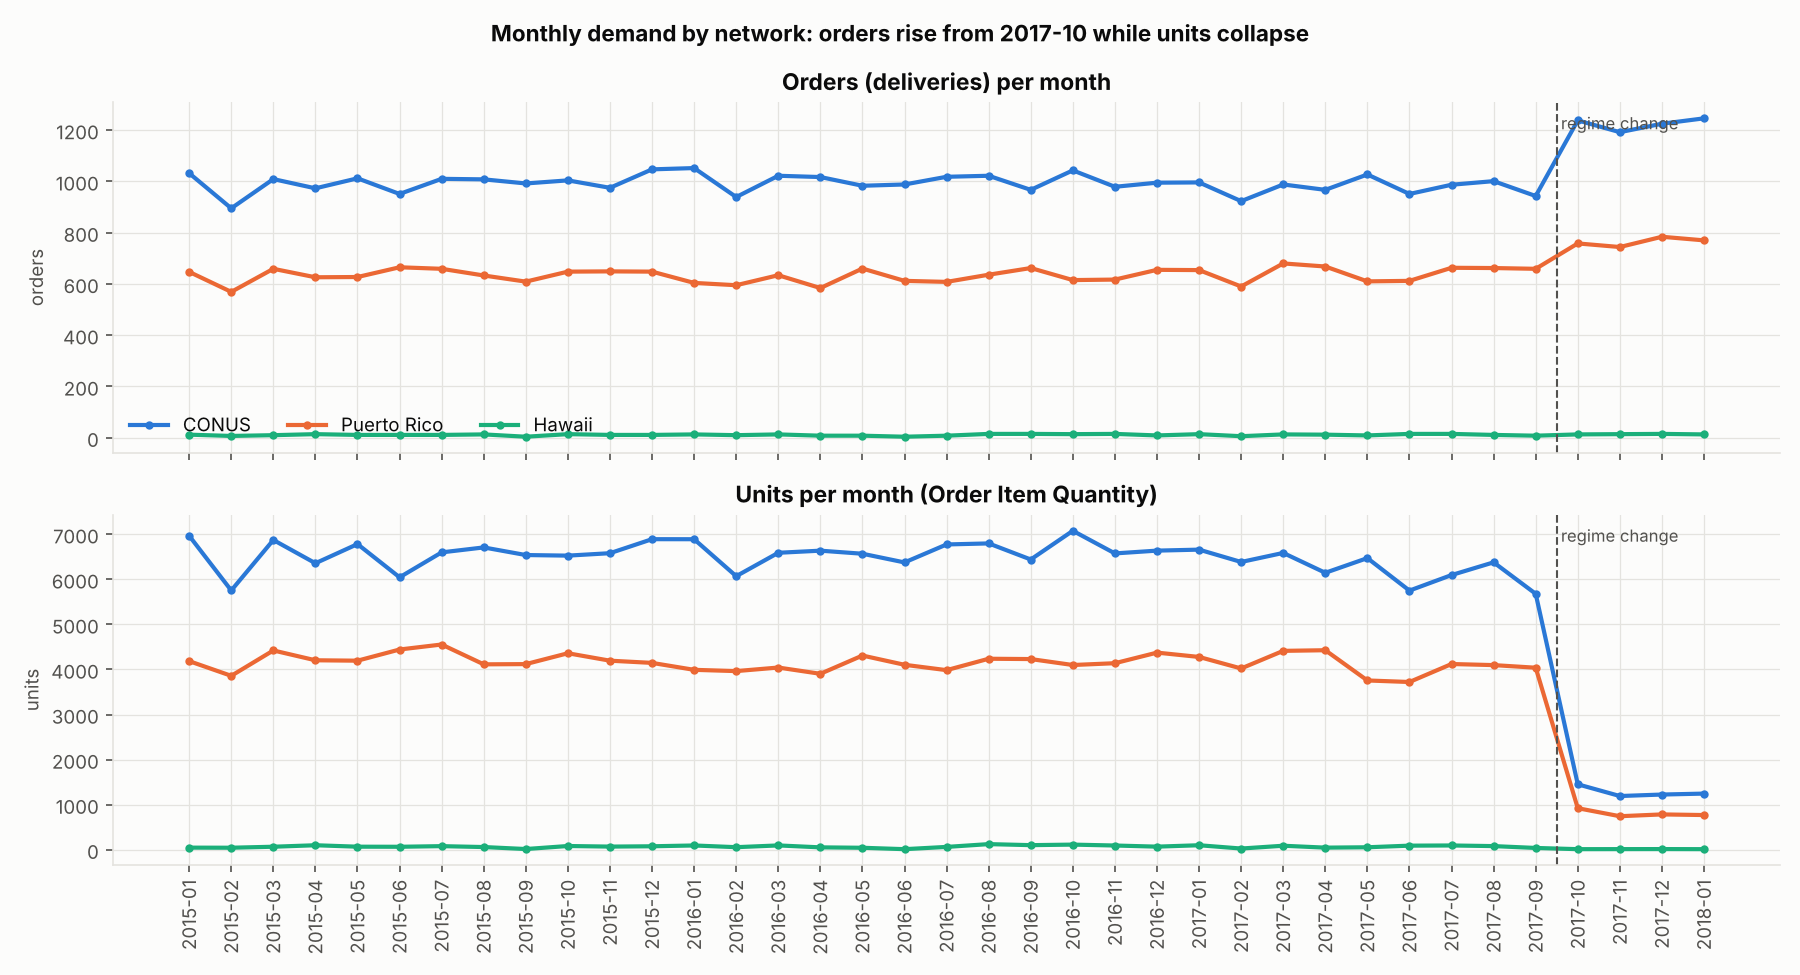

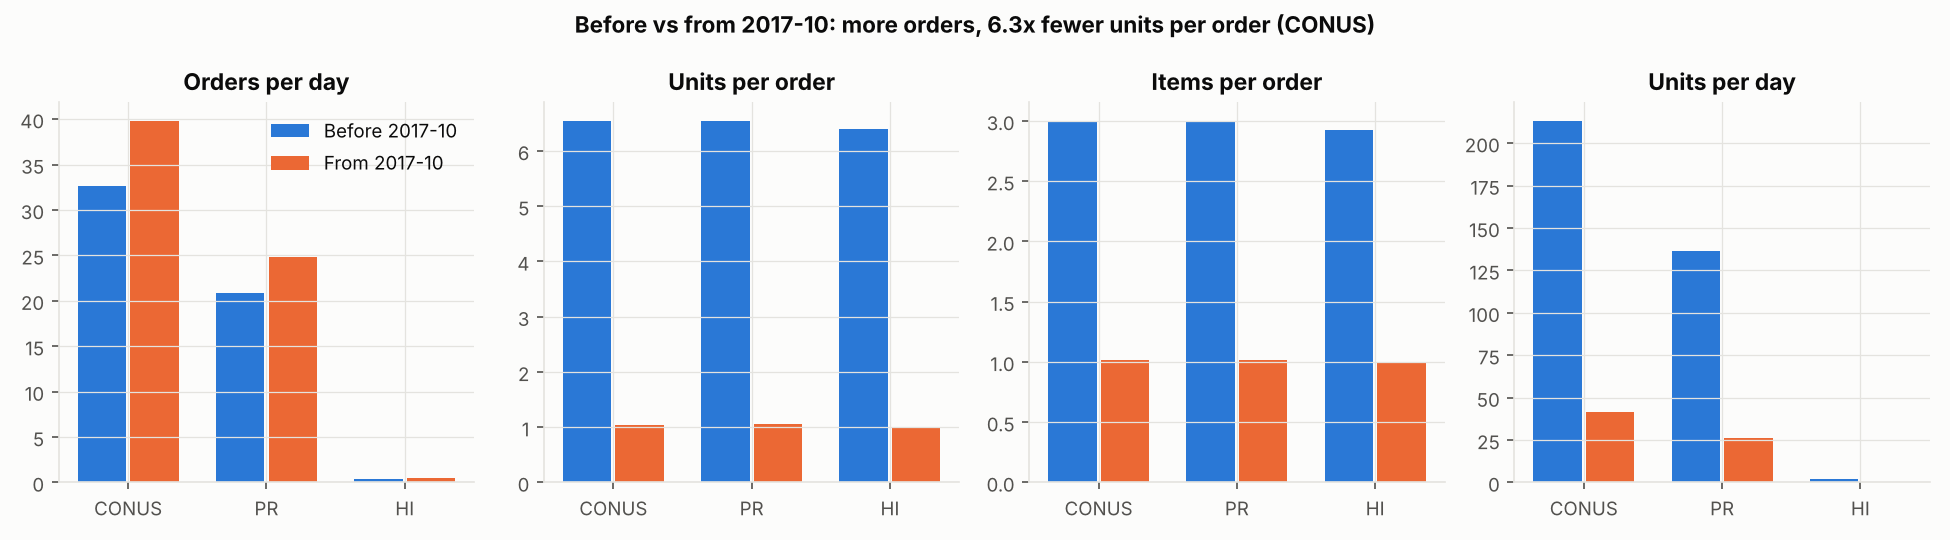

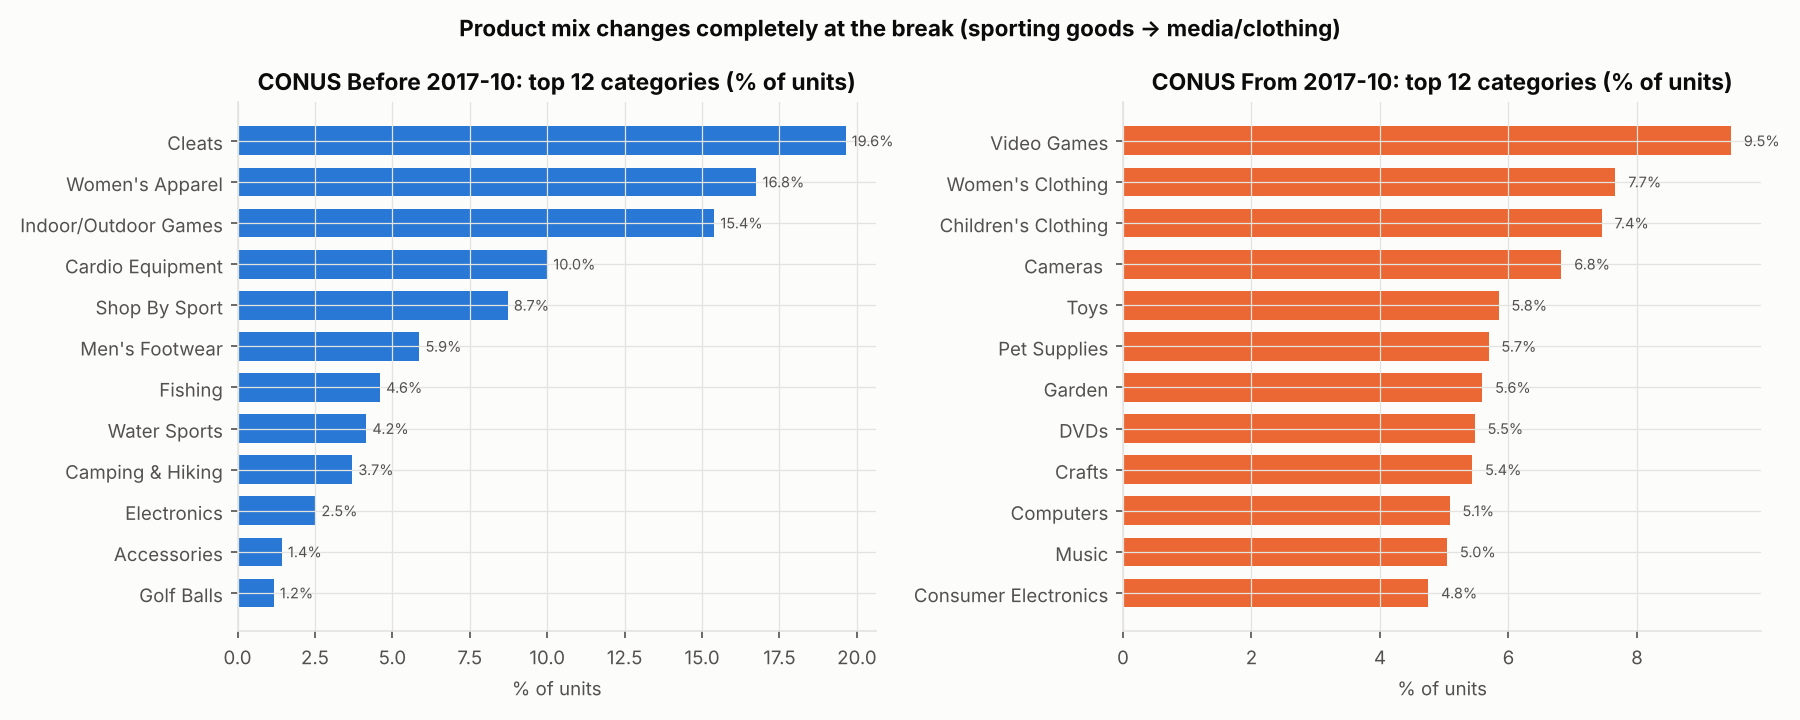

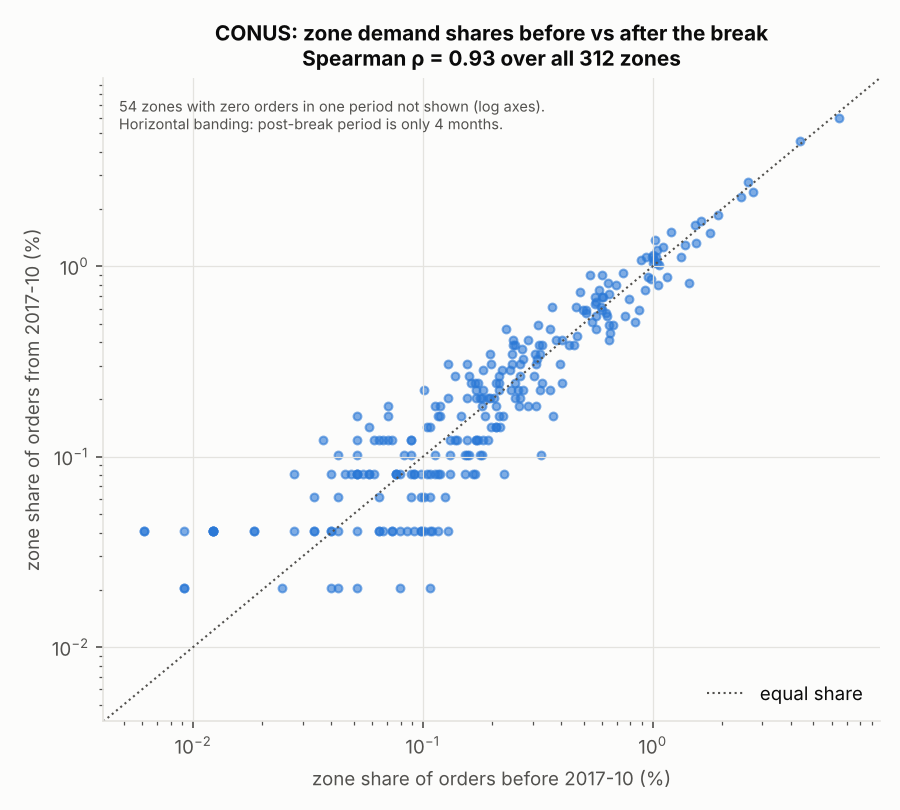

In [6]:
display(tables['regime']); display(tables['stability'])
for f in ['phase2_monthly_demand','phase2_regime_comparison','phase2_category_shift','phase2_zone_spatial_stability']:
    display(Image(f'reports/figures/{f}.png'))

## 6. Temporal structure and sparsity

,network,granularity,zone_periods,zero_share,mean_orders,median_orders
0,CONUS,day,351624,0.911056,0.106981,0.0
1,Hawaii,day,6762,0.940106,0.061964,0.0
2,Puerto Rico,day,28175,0.852706,0.850932,0.0
3,CONUS,week,50544,0.648465,0.744243,0.0
4,Hawaii,week,972,0.658436,0.431070,0.0
5,Puerto Rico,week,4050,0.667160,5.919753,0.0
6,CONUS,month,11544,0.344421,3.258576,1.0
7,Hawaii,month,222,0.216216,1.887387,2.0
8,Puerto Rico,month,925,0.355676,25.918919,1.0


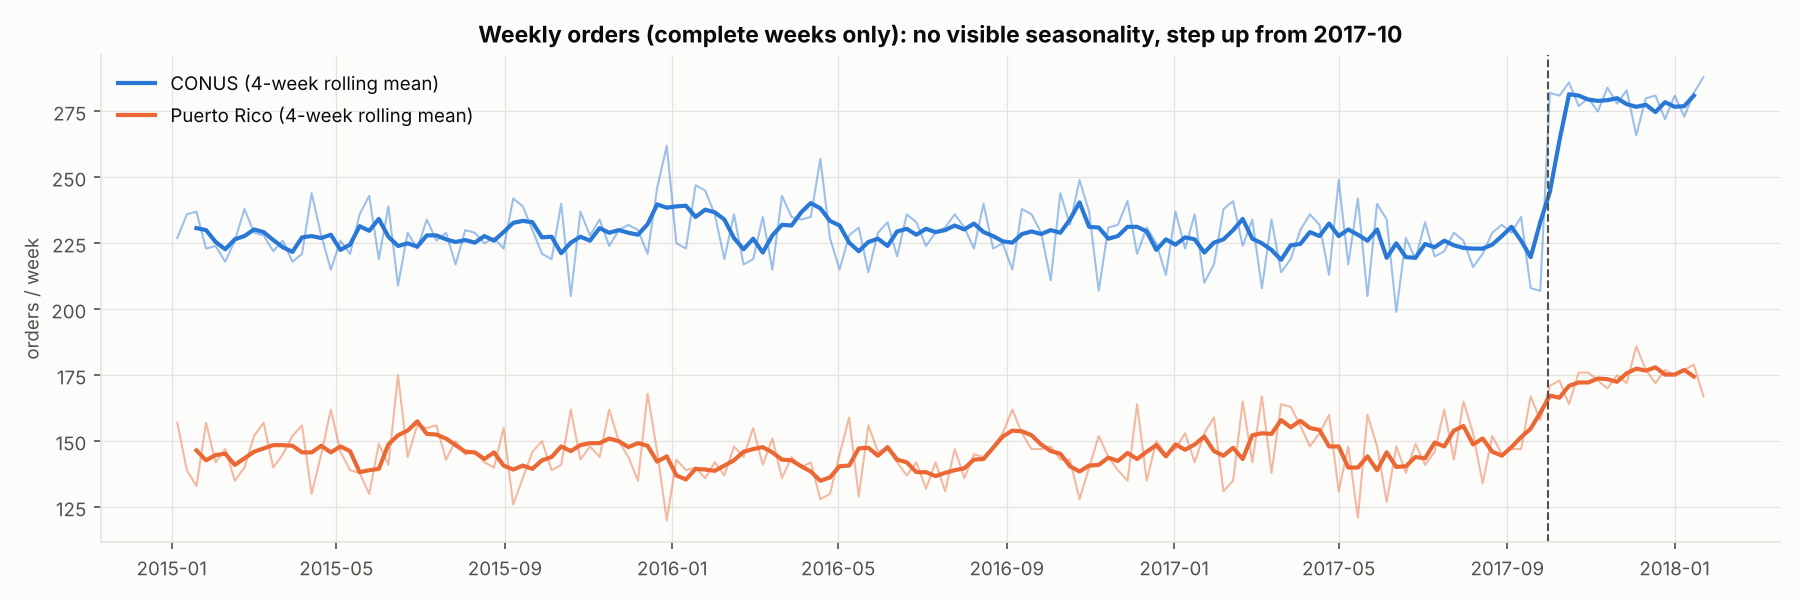

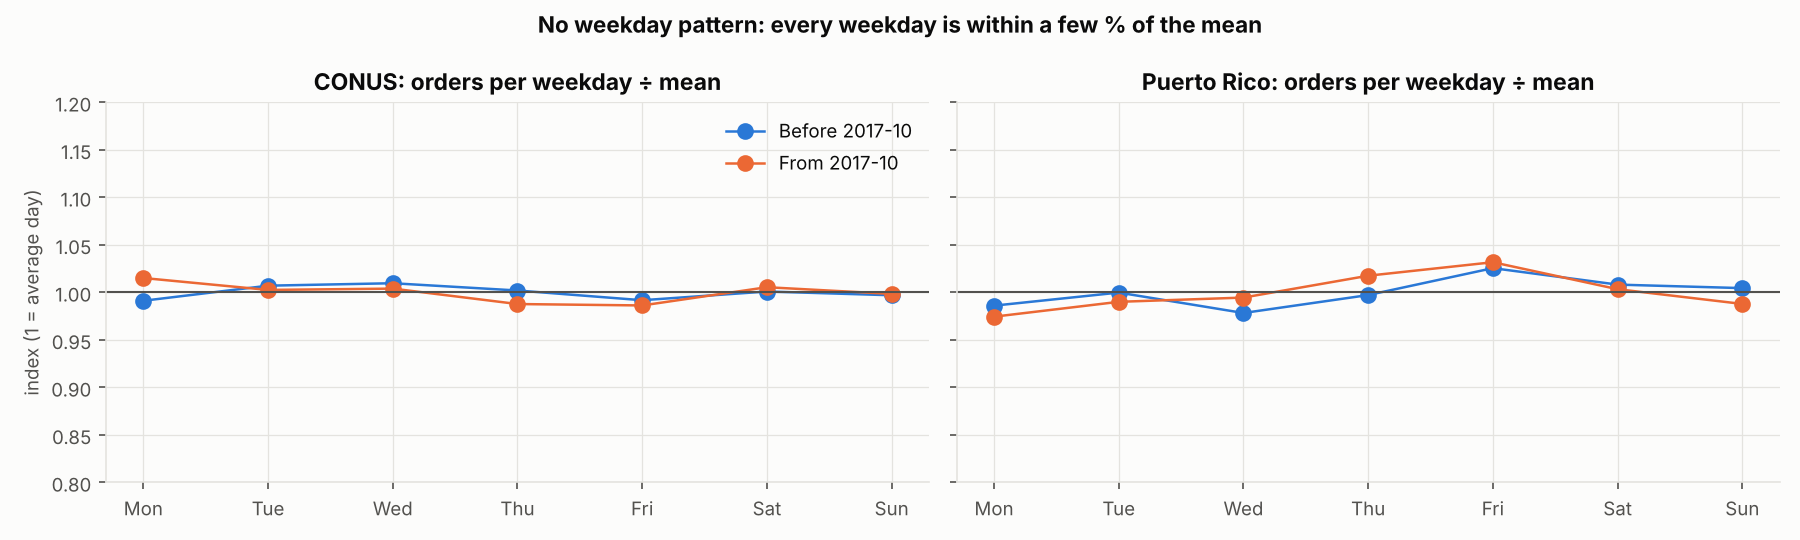

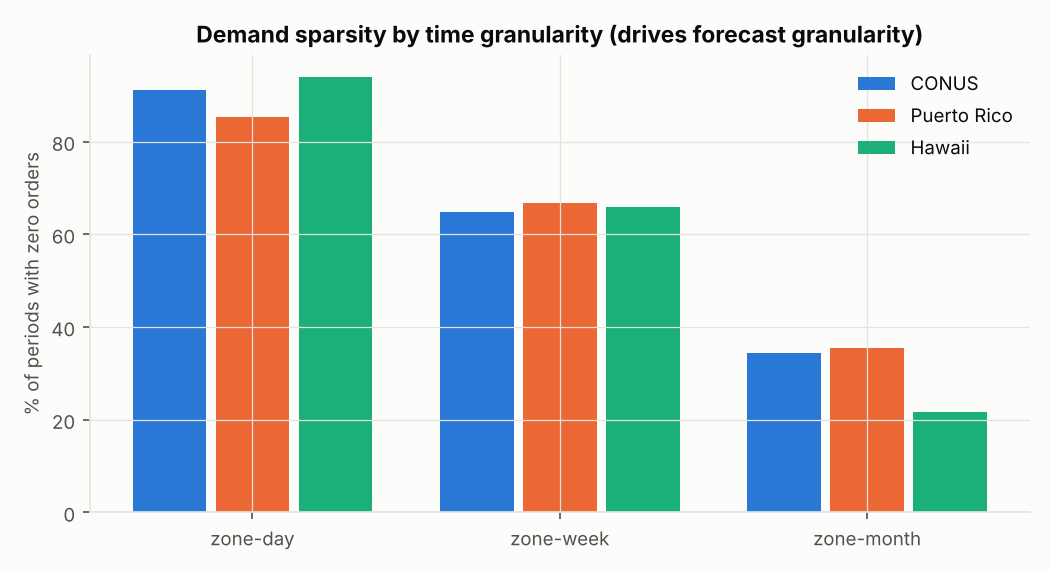

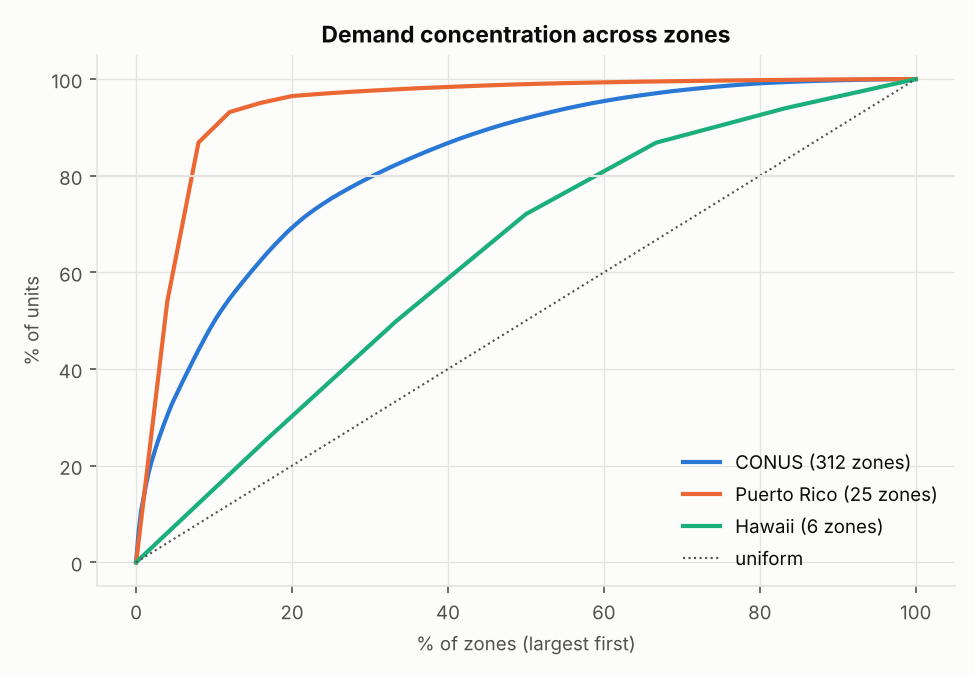

In [7]:
display(tables['sparsity'])
for f in ['phase2_weekly_orders','phase2_day_of_week','phase2_demand_sparsity','phase2_zone_concentration']:
    display(Image(f'reports/figures/{f}.png'))

## 7. EDA summary (`eda_summary.csv`)

In [8]:
tables['summary']

,scope,metric,value,unit,source
0,raw,order-item rows,180519,rows,dataset
1,raw,orders,65752,orders,dataset
2,raw,customers,20652,customers,dataset
3,demand set,order-item rows,170157,rows,dataset
4,demand set,orders (deliveries),62011,orders,dataset
...,...,...,...,...,...
91,Puerto Rico,zero-demand share per zone-month,0.355676,ratio,derived
92,destination,destination_domestic vs network: Cramer's V,0.010472,,derived
93,destination,destination_domestic vs network: p-value,0.033379,,derived
94,destination,destination_domestic vs customer_state (CONUS): Cramer's V,0.039343,,derived
